# Notebook 1 — Solutions to the exercises

These are model solutions for instructors and self-learners. Try the exercises in `notebooks/01_images_and_kspace.ipynb` first.

## Setup (same as Notebook 1)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import resize, rotate

plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(0)  # fixed seed so everyone sees the same results

In [2]:
def fft2c(image):
    """Centered, orthonormal 2D FFT: image -> k-space."""
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image), norm="ortho"))


def ifft2c(kspace):
    """Centered, orthonormal inverse 2D FFT: k-space -> image."""
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace), norm="ortho"))


def log_mag(kspace):
    """Log-scaled magnitude, so both the bright center and the faint edges of k-space are visible."""
    mag = np.abs(kspace)
    return np.log10(mag / mag.max() + 1e-6)  # 0 at the brightest point, about -6 for the faintest


def show(images, titles, cmap="gray", vmin=None, vmax=None):
    """Show images side by side."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
    for ax, im, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [3]:
N = 256
image = resize(shepp_logan_phantom(), (N, N), anti_aliasing=True)
kspace = fft2c(image)
ky_grid, kx_grid = np.meshgrid(np.arange(N) - N // 2, np.arange(N) - N // 2, indexing="ij")
k_radius = np.sqrt(kx_grid**2 + ky_grid**2)

## Exercise 1: half of k-space

With only the left half, the image is darker, smooth regions lose their contrast and edges stand out: missing half of k-space is not harmless. But because the phantom is real-valued, its k-space is conjugate-symmetric, so we can fill in the missing half exactly.

Max error, half k-space only:      0.794
Max error, after symmetry filling: 4.4e-16


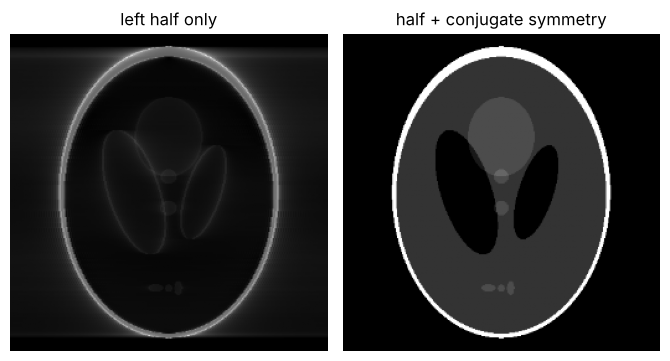

In [4]:
left_half = kx_grid < 0
half_k = kspace * left_half
half_recon = np.abs(ifft2c(half_k))

# Rebuild the missing half: k(ky, kx) = conj(k(-ky, -kx)).
# With an even N, index i maps to (N - i) % N in the centered grid.
idx = (N - np.arange(N)) % N
mirrored = np.conj(half_k[np.ix_(idx, idx)])
filled = np.where(left_half, half_k, mirrored)
# the kx = 0 column was not measured in this split; take it from its own symmetry too
filled[:, N // 2] = kspace[:, N // 2]
filled_recon = np.abs(ifft2c(filled))

print(f"Max error, half k-space only:      {np.abs(half_recon - image).max():.3f}")
print(f"Max error, after symmetry filling: {np.abs(filled_recon - image).max():.1e}")
show([half_recon, filled_recon], ["left half only", "half + conjugate symmetry"], vmin=0, vmax=1)

Note: to keep the example short, the `kx = 0` column is copied from full k-space. In practice it must be measured, which is one reason partial Fourier methods acquire slightly more than half of k-space. Real MR images also have a smooth phase, so real partial Fourier methods estimate that phase from the measured center first.

## Exercise 2: magnitude vs phase

Max change in k-space magnitude: 1.8e-15


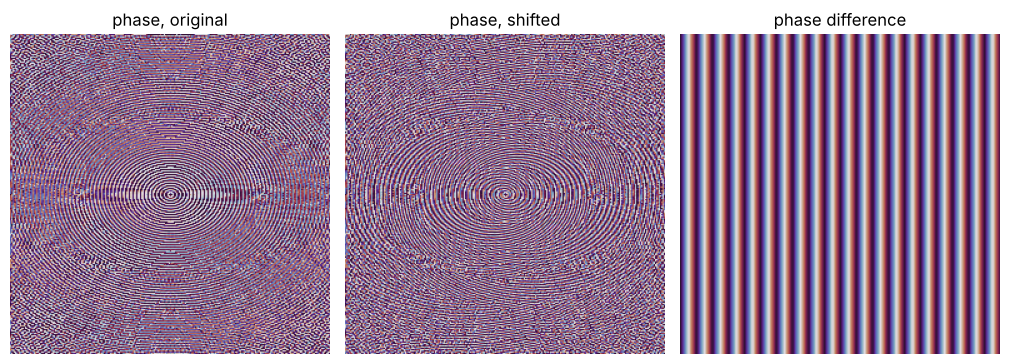

In [5]:
shifted = np.roll(image, 20, axis=1)
k_shift = fft2c(shifted)

print(f"Max change in k-space magnitude: {np.abs(np.abs(k_shift) - np.abs(kspace)).max():.1e}")
phase_diff = np.angle(k_shift * np.conj(kspace))
show([np.angle(kspace), np.angle(k_shift), phase_diff],
     ["phase, original", "phase, shifted", "phase difference"], cmap="twilight")

The magnitude is unchanged; the phase difference is a linear ramp along kx (the shift theorem). Moving an object only changes the phase of its k-space.

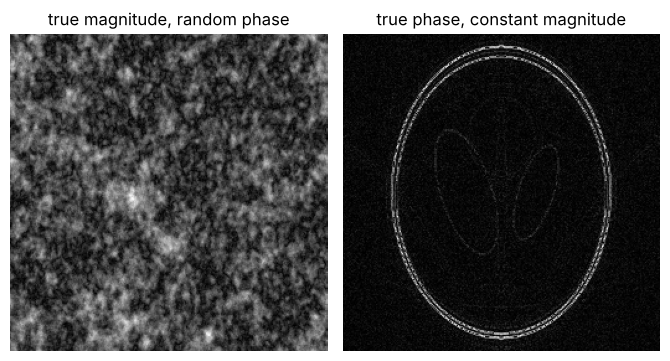

In [6]:
random_phase = rng.uniform(-np.pi, np.pi, size=(N, N))
mag_only = np.abs(ifft2c(np.abs(kspace) * np.exp(1j * random_phase)))
phase_only = np.abs(ifft2c(np.exp(1j * np.angle(kspace))))

show([mag_only, phase_only], ["true magnitude, random phase", "true phase, constant magnitude"])

The phase-only image keeps the edges and the positions of structures; the magnitude-only image is unrecognizable. Phase carries the "where" information. This is why reconstruction must handle complex data and not just magnitudes.

## Exercise 3: energy in the center

radius   2:  39.7% of the energy,  0.02% of the points
radius   4:  48.7% of the energy,  0.07% of the points
radius   8:  60.0% of the energy,  0.30% of the points
radius  16:  75.5% of the energy,  1.22% of the points
radius  32:  90.5% of the energy,  4.90% of the points
radius  64:  97.4% of the energy, 19.61% of the points
radius 128:  99.6% of the energy, 78.48% of the points


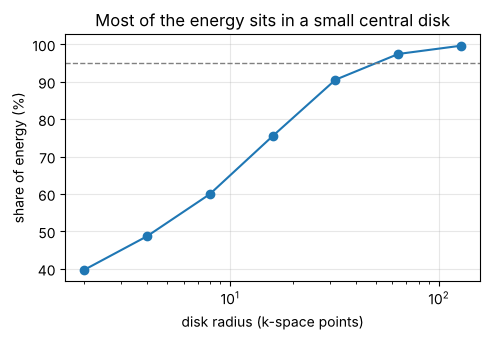

In [7]:
radii = [2, 4, 8, 16, 32, 64, 128]
total = np.sum(np.abs(kspace) ** 2)
shares = [np.sum(np.abs(kspace[k_radius <= r]) ** 2) / total for r in radii]

for r, s in zip(radii, shares):
    print(f"radius {r:>3}: {s:6.1%} of the energy, {np.mean(k_radius <= r):6.2%} of the points")

plt.figure(figsize=(5, 3.5))
plt.semilogx(radii, np.array(shares) * 100, "o-")
plt.axhline(95, color="gray", ls="--", lw=1)
plt.xlabel("disk radius (k-space points)")
plt.ylabel("share of energy (%)")
plt.title("Most of the energy sits in a small central disk")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A very small share of the points near the center holds most of the energy. Sampling the center densely and the edges sparsely, called **variable-density sampling**, is therefore a good way to spend limited scan time. Notebook 2 builds on this.

## Exercise 4: rotation

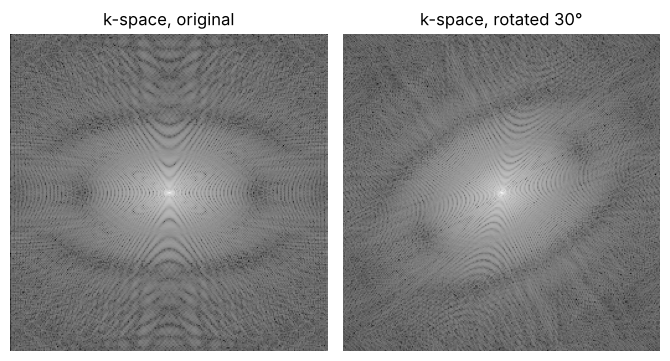

In [8]:
rotated = rotate(image, 30)
show([log_mag(kspace), log_mag(fft2c(rotated))], ["k-space, original", "k-space, rotated 30°"])

The k-space magnitude rotates by the same 30°. Rotating the object rotates every stripe pattern it is made of, and each stripe pattern's direction is its direction from the k-space center (Section 4).